In [11]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import glob
from torchvision.datasets import CIFAR10
import torchvision.transforms as transforms
import contextlib, torch, torch.nn as nn, torch.optim as optim
from torchvision import models
from opacus import PrivacyEngine
from opacus.validators import ModuleValidator
from opacus.utils.batch_memory_manager import BatchMemoryManager
from types import MethodType
from torchvision.models.resnet import BasicBlock
from torch.utils.data import Subset
import os, json, time
import warnings
warnings.simplefilter("ignore")

In [ ]:
SAVE_DIR = "dp_cifar_experiments"
os.makedirs(SAVE_DIR, exist_ok=True)

In [3]:
MAX_GRAD_NORM = 1.2
DELTA = 1e-5
EPOCHS = 20
LR = 1e-3

In [4]:
BATCH_SIZE = 512
MAX_PHYSICAL_BATCH_SIZE = 128

In [5]:
# These values, specific to the CIFAR10 dataset, are assumed to be known.
# If necessary, they can be computed with modest privacy budgets.
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD_DEV = (0.2023, 0.1994, 0.2010)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD_DEV),
])

In [6]:
DATA_ROOT = '../cifar10'

train_dataset = CIFAR10(
    root=DATA_ROOT, train=True, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
)

test_dataset = CIFAR10(
    root=DATA_ROOT, train=False, download=True, transform=transform)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [ ]:
def plot_compare(results):   
    x = np.arange(len(CLASSES))
    w = 0.8 / len(results)
    for i, (label, accs) in enumerate(results.items()):
        plt.bar(x + i * w, [accs[c] * 100 for c in CLASSES], w, label=label)
    plt.xticks(x + 0.4 - w / 2, CLASSES, rotation=45)
    plt.ylabel("Accuracy (%)")
    plt.legend(loc="upper center", ncol=3)
    plt.ylim(0,100)
    plt.tight_layout()
    plt.show()

In [ ]:
def make_imbalanced(dataset, rare_class=3, keep=500, seed=0):
    
    rng = np.random.RandomState(seed)
    targets = np.array(dataset.targets)
    keep_idx = []
    for c in range(10):
        idx = np.where(targets == c)[0]
        if c == rare_class:
            idx = rng.choice(idx, size=keep, replace=False)
        keep_idx.extend(idx.tolist())
    return Subset(dataset, keep_idx)

In [7]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]

def test_per_class(model, test_loader, device):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, target in test_loader:
            images = images.to(device)
            output = model(images)
            preds = output.argmax(dim=1).cpu().numpy()
            all_preds.append(preds)
            all_labels.append(target.numpy())

    preds = np.concatenate(all_preds)
    labels = np.concatenate(all_labels)


    overall = (preds == labels).mean()
    print(f"Overall accuracy: {overall * 100:.2f}%\n")


    per_class = {}
    for c, name in enumerate(CLASSES):
        mask = labels == c                      
        acc = (preds[mask] == labels[mask]).mean()
        per_class[name] = acc
        print(f"{name:12s} {acc * 100:6.2f}%")

    worst = min(per_class, key=per_class.get)
    print(f"\nWorst class: {worst} ({per_class[worst] * 100:.2f}%)")
    return per_class

In [28]:
# Opacus computes per-sample gradients with backward hooks that need the
# activations saved during the forward pass to stay unchanged. In-place ops
# overwrite those tensors and raise an error during DP training.
# torchvision's BasicBlock uses `out += identity` (in-place), so we override
# its forward with an equivalent version that uses `out + identity` instead.
def residual_forward(self, x):
    identity = x if self.downsample is None else self.downsample(x)
    out = self.relu(self.bn1(self.conv1(x)))
    out = self.bn2(self.conv2(out))
    return self.relu(out + identity)

In [17]:
def build_model():
    model = models.resnet18(num_classes=10)
    model = ModuleValidator.fix(model)           
    for layer in model.modules():                 
        if isinstance(layer, nn.ReLU):
            layer.inplace = False       # ReLU(inplace=True) breaks Opacus hooks
        if isinstance(layer, BasicBlock):
            layer.forward = MethodType(residual_forward, layer)    # replace in-place residual add
    return model.to(device)

def run_experiment(epsilon=None, seed=0, dataset=None):
    dataset = dataset if dataset is not None else train_dataset
    torch.manual_seed(seed)
    model = build_model()
    optimizer = optim.RMSprop(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()

    
    loader = torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

    if epsilon is not None:
        privacy_engine = PrivacyEngine()
        model, optimizer, loader = privacy_engine.make_private_with_epsilon(
            module=model, optimizer=optimizer, data_loader=loader,
            epochs=EPOCHS, target_epsilon=epsilon,
            target_delta=DELTA, max_grad_norm=MAX_GRAD_NORM,
        )
        print(f"sigma = {optimizer.noise_multiplier:.3f}")

    for epoch in range(EPOCHS):
        model.train()
        if epsilon is None:
            ctx = contextlib.nullcontext(loader)            
        else:
            ctx = BatchMemoryManager(data_loader=loader,
                                     max_physical_batch_size=MAX_PHYSICAL_BATCH_SIZE,
                                     optimizer=optimizer)
        with ctx as data:
            for images, target in data:
                optimizer.zero_grad()
                images, target = images.to(device), target.to(device)
                loss = criterion(model(images), target)
                loss.backward()
                optimizer.step()
        print(f"epoch {epoch + 1}/{EPOCHS} done")

    if epsilon is not None:
        print(f"final epsilon spent: {privacy_engine.get_epsilon(DELTA):.2f}")
    return test_per_class(model, test_loader, device)    

In [ ]:
def run_and_save(name, epsilon, dataset=None, seed=0):
    path = os.path.join(SAVE_DIR, f"{name}_seed{seed}.json")

    
    if os.path.exists(path):
        print(f"[skip] {name} (seed {seed}) already done")
        with open(path) as f:
            return json.load(f)["per_class"]

    print(f"[run] {name} (seed {seed})")
    t0 = time.time()
    per_class = run_experiment(epsilon=epsilon, seed=seed, dataset=dataset)
    minutes = (time.time() - t0) / 60

    record = {
        "name": name,
        "epsilon": epsilon,
        "seed": seed,
        "device": gpu,
        "train_minutes": round(minutes, 1),
        "epochs": EPOCHS,
        "max_grad_norm": MAX_GRAD_NORM,
        "delta": DELTA,
        "per_class": {k: float(v) for k, v in per_class.items()},
    }
    with open(path, "w") as f:
        json.dump(record, f, indent=2)
    print(f"[saved] {path} ({minutes:.1f} min)")
    return record["per_class"]

In [ ]:
def load_all():
    out = {}
    for p in sorted(glob.glob(os.path.join(SAVE_DIR, "*.json"))):
        with open(p) as f:
            r = json.load(f)
        out[f'{r["name"]} (seed {r["seed"]})'] = r["per_class"]
    return out

#all_results = load_all()

In [18]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

In [26]:
# Class-imbalance experiment: downsample "cat" (class 3) to 500 training images
imb_train = make_imbalanced(train_dataset, rare_class=3, keep=500)
results_imb = {}
results_imb["baseline_imb"] = run_and_save("baseline_imb", None, dataset=imb_train)
results_imb["eps8_imb"]     = run_and_save("eps8_imb", 8.0, dataset=imb_train)
results_imb["eps2_imb"]     = run_and_save("eps2_imb", 2.0, dataset=imb_train)
plot_compare(results_imb)

In [19]:
results = {}

In [20]:
results["baseline"] = run_and_save("baseline", None)

epoch 1/20 done
epoch 2/20 done
epoch 3/20 done
epoch 4/20 done
epoch 5/20 done
epoch 6/20 done
epoch 7/20 done
epoch 8/20 done
epoch 9/20 done
epoch 10/20 done
epoch 11/20 done
epoch 12/20 done
epoch 13/20 done
epoch 14/20 done
epoch 15/20 done
epoch 16/20 done
epoch 17/20 done
epoch 18/20 done
epoch 19/20 done
epoch 20/20 done
Overall accuracy: 67.99%

airplane      72.90%
automobile    75.80%
bird          62.10%
cat           64.00%
deer          54.70%
dog           42.90%
frog          77.60%
horse         69.40%
ship          79.80%
truck         80.70%

Worst class: dog (42.90%)


In [21]:
results["ε=8"] = run_and_save("eps8", 8.0)

sigma = 0.646
epoch 1/20 done
epoch 2/20 done
epoch 3/20 done
epoch 4/20 done
epoch 5/20 done
epoch 6/20 done
epoch 7/20 done
epoch 8/20 done
epoch 9/20 done
epoch 10/20 done
epoch 11/20 done
epoch 12/20 done
epoch 13/20 done
epoch 14/20 done
epoch 15/20 done
epoch 16/20 done
epoch 17/20 done
epoch 18/20 done
epoch 19/20 done
epoch 20/20 done
final epsilon spent: 7.99
Overall accuracy: 56.91%

airplane      61.50%
automobile    71.60%
bird          38.30%
cat           30.60%
deer          42.50%
dog           52.70%
frog          72.50%
horse         63.70%
ship          70.70%
truck         65.00%

Worst class: cat (30.60%)


In [22]:
results["ε=2"] = run_and_save("eps2", 2.0)

sigma = 1.162
epoch 1/20 done
epoch 2/20 done
epoch 3/20 done
epoch 4/20 done
epoch 5/20 done
epoch 6/20 done
epoch 7/20 done
epoch 8/20 done
epoch 9/20 done
epoch 10/20 done
epoch 11/20 done
epoch 12/20 done
epoch 13/20 done
epoch 14/20 done
epoch 15/20 done
epoch 16/20 done
epoch 17/20 done
epoch 18/20 done
epoch 19/20 done
epoch 20/20 done
final epsilon spent: 2.00
Overall accuracy: 50.65%

airplane      56.20%
automobile    65.50%
bird          31.00%
cat           26.20%
deer          33.60%
dog           45.50%
frog          69.00%
horse         60.20%
ship          64.30%
truck         55.00%

Worst class: cat (26.20%)


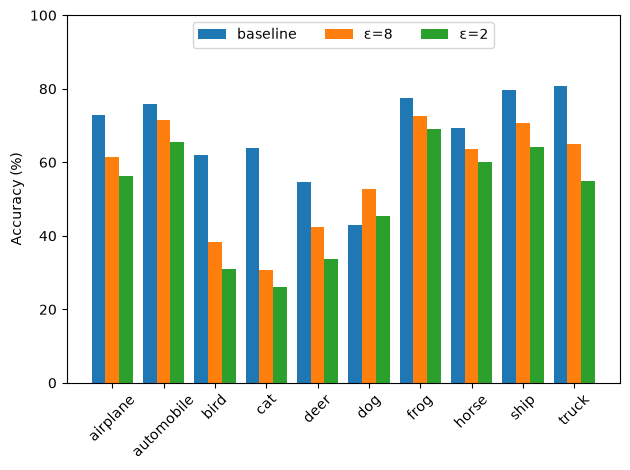

In [24]:
plot_compare(results)